# Experiment: Titanic EDA

Objective:
- Explore the Titanic passenger dataset and identify the strongest signals associated with survival.
- Produce a notebook that can run with either a local CSV or Seaborn's built-in Titanic sample.


In [1]:
# Setup: imports and reproducibility
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

SEED = 7
sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

SEED


7

## Plan

- Hypothesis: survival is strongly related to sex, passenger class, and fare.
- Variables to inspect: age, fare, sex, pclass, embarked, family size.
- Metrics to record: missingness, survival rate, and group-level summaries.


In [2]:
# Load data from a local CSV when available, otherwise fall back to Seaborn's sample dataset.
def load_titanic() -> tuple[pd.DataFrame, str]:
    candidates = [
        Path("data/titanic.csv"),
        Path("../data/titanic.csv"),
        Path("titanic.csv"),
    ]
    for path in candidates:
        if path.exists():
            return pd.read_csv(path), f"local file: {path}"
    return sns.load_dataset("titanic").copy(), "seaborn.load_dataset('titanic')"


df, data_source = load_titanic()
df = df.rename(columns=str.lower)
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Dataset Overview

Check the data source, shape, and column types before digging into patterns.


In [3]:
overview = {
    "source": data_source,
    "rows": len(df),
    "columns": df.shape[1],
    "survival_rate": df["survived"].mean() if "survived" in df.columns else None,
}
overview


{'source': "seaborn.load_dataset('titanic')",
 'rows': 891,
 'columns': 15,
 'survival_rate': 0.3838383838383838}

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Missing Data

Missingness matters here because the Titanic dataset has several partially observed fields.


,missing_rate
deck,0.772166
age,0.198653
embarked,0.002245
embark_town,0.002245
survived,0.000000
pclass,0.000000
sex,0.000000
sibsp,0.000000
parch,0.000000
fare,0.000000


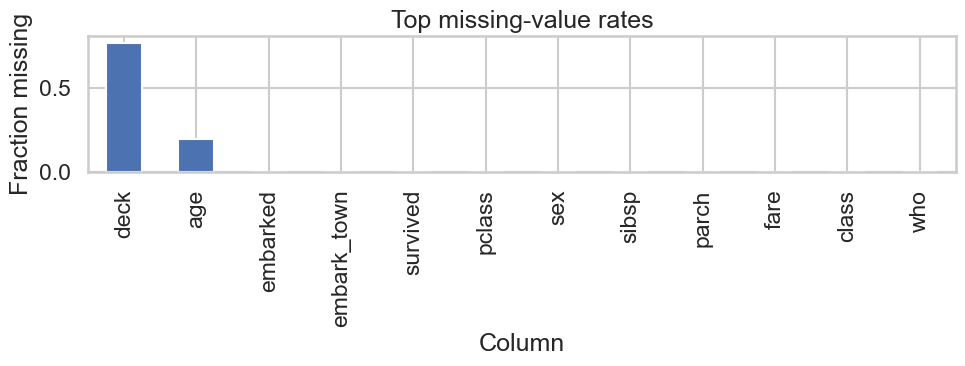

In [6]:
missing = (
    df.isna()
    .mean()
    .sort_values(ascending=False)
    .rename("missing_rate")
    .to_frame()
)
display(missing.head(12))

ax = missing.head(12).plot(kind="bar", legend=False, figsize=(10, 4), color="#4C72B0")
ax.set_title("Top missing-value rates")
ax.set_ylabel("Fraction missing")
ax.set_xlabel("Column")
plt.tight_layout()


## Survival By Segment

Start with the most informative categorical splits: sex, class, and embarkation port.


In [7]:
group_cols = [col for col in ["sex", "pclass", "embarked"] if col in df.columns]
for col in group_cols:
    summary = df.groupby(col)["survived"].agg(["count", "mean"]).sort_values("mean", ascending=False)
    display(summary)


,count,mean
sex,,
female,314,0.742038
male,577,0.188908


,count,mean
pclass,,
1,216,0.629630
2,184,0.472826
3,491,0.242363


,count,mean
embarked,,
C,168,0.553571
Q,77,0.389610
S,644,0.336957


C:\Users\mikec\AppData\Local\Temp\ipykernel_12800\3808391069.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="sex", y="survived", ax=axes[0], errorbar=None, palette="deep")
C:\Users\mikec\AppData\Local\Temp\ipykernel_12800\3808391069.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="pclass", y="survived", ax=axes[1], errorbar=None, palette="deep")
C:\Users\mikec\AppData\Local\Temp\ipykernel_12800\3808391069.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="embarked", y="survived", ax=axes[2], error

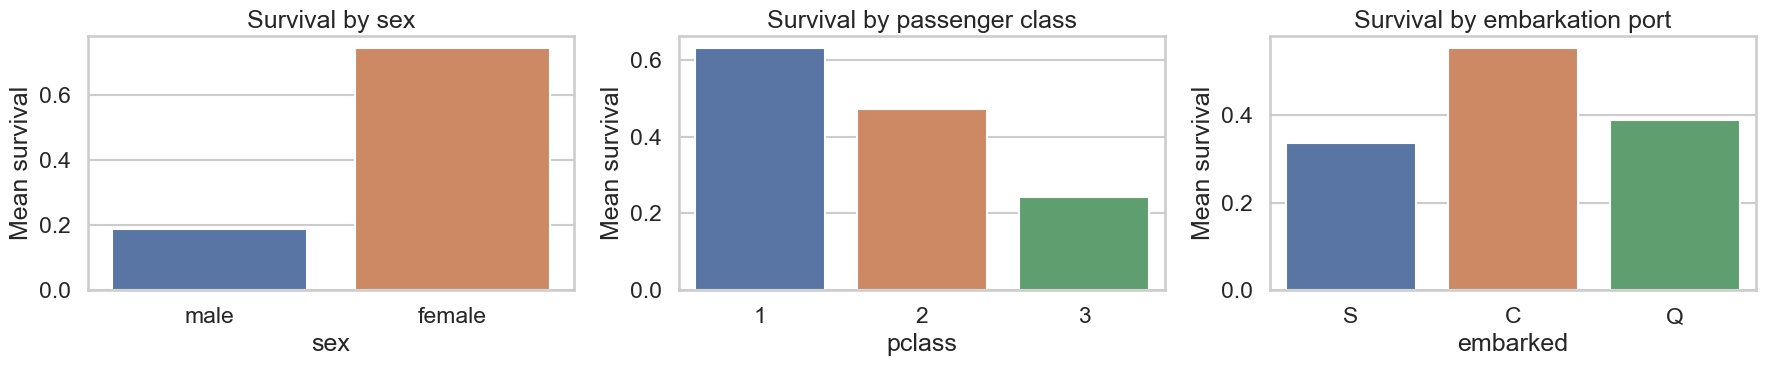

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.barplot(data=df, x="sex", y="survived", ax=axes[0], errorbar=None, palette="deep")
axes[0].set_title("Survival by sex")
axes[0].set_ylabel("Mean survival")

sns.barplot(data=df, x="pclass", y="survived", ax=axes[1], errorbar=None, palette="deep")
axes[1].set_title("Survival by passenger class")
axes[1].set_ylabel("Mean survival")

if "embarked" in df.columns:
    sns.barplot(data=df, x="embarked", y="survived", ax=axes[2], errorbar=None, palette="deep")
    axes[2].set_title("Survival by embarkation port")
    axes[2].set_ylabel("Mean survival")
else:
    axes[2].axis("off")

plt.tight_layout()


## Numeric Features

Age and fare often carry useful signal, but both are skewed and incomplete, so inspect them with care.


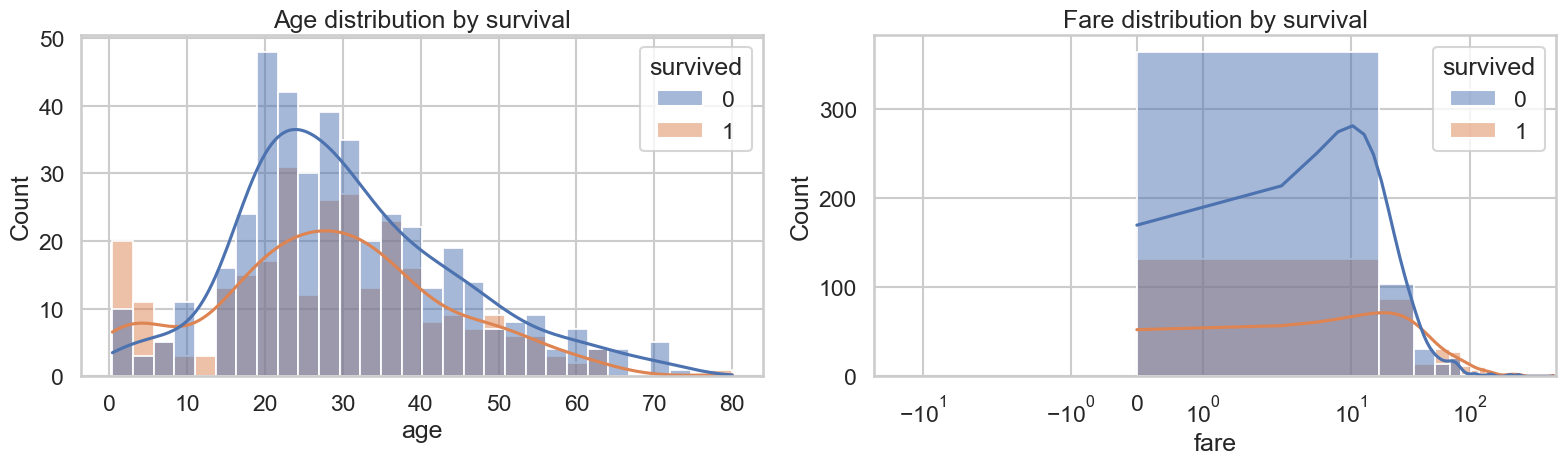

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

if "age" in df.columns:
    sns.histplot(data=df, x="age", hue="survived", kde=True, bins=30, ax=axes[0], palette="deep")
    axes[0].set_title("Age distribution by survival")
else:
    axes[0].axis("off")

if "fare" in df.columns:
    sns.histplot(data=df, x="fare", hue="survived", kde=True, bins=30, ax=axes[1], palette="deep")
    axes[1].set_title("Fare distribution by survival")
    axes[1].set_xscale("symlog")
else:
    axes[1].axis("off")

plt.tight_layout()


In [10]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
corr = df[numeric_cols].corr(numeric_only=True) if numeric_cols else pd.DataFrame()
corr


,survived,pclass,age,sibsp,parch,fare
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


## Feature Engineering

A simple family-size feature can capture whether traveling alone or with relatives changes survival odds.


,count,mean
family_size,,
1,537,0.303538
2,161,0.552795
3,102,0.578431
4,29,0.724138
5,15,0.200000
6,22,0.136364
7,12,0.333333
8,6,0.000000
11,7,0.000000


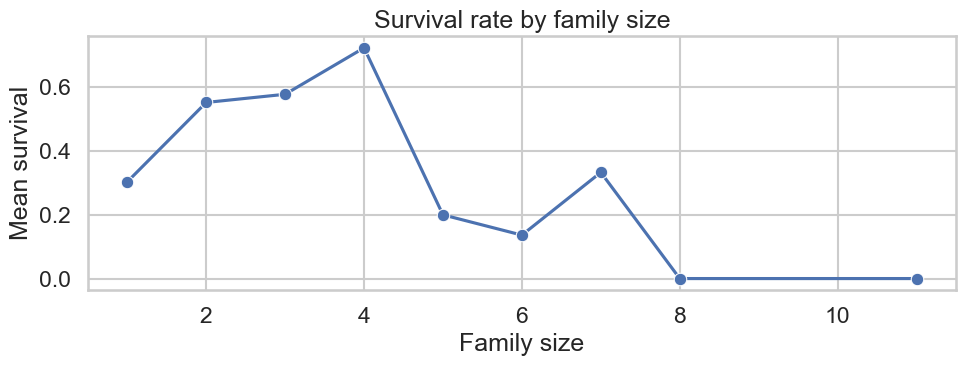

In [11]:
working = df.copy()
if {"sibsp", "parch"}.issubset(working.columns):
    working["family_size"] = working["sibsp"] + working["parch"] + 1
    working["is_alone"] = (working["family_size"] == 1).astype(int)

    family_summary = working.groupby("family_size", dropna=False)["survived"].agg(["count", "mean"]).sort_index()
    display(family_summary.head(10))

    fig, ax = plt.subplots(figsize=(10, 4))
    sns.lineplot(data=family_summary.reset_index(), x="family_size", y="mean", marker="o", ax=ax)
    ax.set_title("Survival rate by family size")
    ax.set_ylabel("Mean survival")
    ax.set_xlabel("Family size")
    plt.tight_layout()
else:
    "sibsp/parch columns not available in this dataset version"


## Results

- Strongest signals to verify: sex, class, and fare.
- Watch for: missing age values, skewed fare, and dataset-version differences in column names.
- Decision: continue with imputation and a predictive baseline if you want modeling next.


In [12]:
result = {
    "source": data_source,
    "rows": len(df),
    "survival_rate": overview["survival_rate"],
    "missing_columns": missing[missing["missing_rate"] > 0].index.tolist(),
}
result


{'source': "seaborn.load_dataset('titanic')",
 'rows': 891,
 'survival_rate': 0.3838383838383838,
 'missing_columns': ['deck', 'age', 'embarked', 'embark_town']}

## Next Steps

- Add imputation for age and embarkation if you plan to model survival.
- Compare a simple logistic regression baseline against tree-based models.
- Save the cleaned dataframe for downstream modeling notebooks.
